In [15]:
import os, sys
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "workbook" else os.getcwd())


In [7]:
agg_holdings = pd.read_csv(os.path.join("data", "processed", "latest_AGG_holdings.CSV"))
bond_features = pd.read_csv(os.path.join("data", "processed", "bond_features.csv"))

In [5]:
bond_features.head()

,cusip,name,ishares_sector,asset_class,agg_market_value,agg_par_value,agg_duration,agg_mod_duration,agg_ytm_pct,agg_weight_raw,model_sector,issue_date,maturity_date,coupon_pct,coupon_frequency,day_count,is_amortising,min_denomination,terms_source,agg_weight
0,91282CMM0,TREASURY NOTE,Treasury,Fixed Income,5.573387e+08,563326000.0,6.70,6.70,4.94,0.0040,treasury,2025-02-15,2035-02-15,4.625,2,ACT/ACT,False,100.0,wrds,0.008065
1,91282CGQ8,TREASURY NOTE,Treasury,Fixed Income,5.507352e+08,559636000.0,3.03,3.03,4.78,0.0040,treasury,2023-02-28,2030-02-28,4.000,2,ACT/ACT,False,100.0,wrds,0.008065
2,91282CLW9,TREASURY NOTE,Treasury,Fixed Income,5.393123e+08,552671000.0,6.53,6.54,4.93,0.0039,treasury,2024-11-15,2034-11-15,4.250,2,ACT/ACT,False,100.0,wrds,0.007863
3,91282CKQ3,TREASURY NOTE,Treasury,Fixed Income,5.381968e+08,544734000.0,6.17,6.17,4.91,0.0039,treasury,2024-05-15,2034-05-15,4.375,2,ACT/ACT,False,100.0,wrds,0.007863
4,91282CLF6,TREASURY NOTE,Treasury,Fixed Income,5.360888e+08,569018000.0,6.51,6.51,4.92,0.0039,treasury,2024-08-15,2034-08-15,3.875,2,ACT/ACT,False,100.0,wrds,0.007863


In [9]:
agg_holdings.head()

,Name,Sector,Asset Class,Market Value,Weight (%),Notional Value,Par Value,CUSIP,ISIN,SEDOL,...,Maturity,Coupon (%),Mod. Duration,Yield to Call (%),Yield to Worst (%),Real Duration,Real YTM (%),Market Currency,Accrual Date,Effective Date
0,BLACKROCK CASH CL INST SL AGENCY,Cash and/or Derivatives,Money Market,"3,658,097,494.54",2.63,"3,658,097,494.54","3,657,366,021.00",066922519,US0669225197,BKGRT85,...,-,3.88,0.22,-,4.04,0.18,4.04,USD,-,"Feb 04, 2009"
1,TREASURY NOTE,Treasury,Fixed Income,"562,248,715.56",0.40,"562,248,715.56","563,326,000.00",91282CMM0,US91282CMM00,BRXZ4W0,...,"Feb 15, 2035",4.63,6.73,-,4.81,6.73,4.81,USD,"Feb 15, 2025","Feb 18, 2025"
2,TREASURY NOTE,Treasury,Fixed Income,"553,504,591.56",0.40,"553,504,591.56","559,636,000.00",91282CGQ8,US91282CGQ87,BMTY6J7,...,"Feb 28, 2030",4.00,3.04,-,4.60,3.04,4.60,USD,"Feb 28, 2023","Feb 28, 2023"
3,TREASURY NOTE,Treasury,Fixed Income,"550,114,395.90",0.40,"550,114,395.90","560,863,000.00",91282CNC1,US91282CNC19,BPJK9X1,...,"May 15, 2035",4.25,6.89,-,4.82,6.89,4.82,USD,"May 15, 2025","May 15, 2025"
4,TREASURY NOTE (OLD),Treasury,Fixed Income,"549,443,732.13",0.40,"549,443,732.13","558,063,000.00",91282CQQ7,US91282CQQ77,BSHW963,...,"May 15, 2036",4.38,7.51,-,4.85,7.51,4.85,USD,"May 15, 2026","May 15, 2026"


In [14]:
print(agg_holdings['Sector'].unique())
bond_features['model_sector'].unique()

['Cash and/or Derivatives' 'Treasury' 'MBS Pass-Through' 'Agency' 'CMBS'
 'Industrial' 'Supranational' 'Financial Institutions' 'Local Authority'
 'ABS' 'Sovereign' 'Utility']


array(['treasury', 'mbs_passthrough', 'industrial', 'financial',
       'utility'], dtype=object)

([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11],
 [Text(0, 0, 'ABS'),
  Text(1, 0, 'Agency'),
  Text(2, 0, 'CMBS'),
  Text(3, 0, 'Cash and/or Derivatives'),
  Text(4, 0, 'Financial Institutions'),
  Text(5, 0, 'Industrial'),
  Text(6, 0, 'Local Authority'),
  Text(7, 0, 'MBS Pass-Through'),
  Text(8, 0, 'Sovereign'),
  Text(9, 0, 'Supranational'),
  Text(10, 0, 'Treasury'),
  Text(11, 0, 'Utility')])

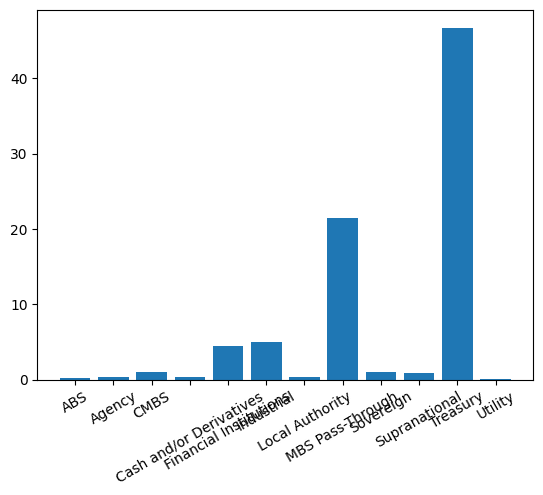

In [22]:
agg_sectors = agg_holdings.groupby('Sector')[['Weight (%)']].sum()
plt.bar(agg_sectors.index, agg_sectors['Weight (%)'])
plt.xticks(rotation = 30)

In [ ]:

bond_features.groupby("model_sector")[["agg_weight_raw", "agg_weight"]].sum()

,agg_weight_raw,agg_weight
model_sector,,
financial,0.0329,0.066331
industrial,0.0345,0.069556
mbs_passthrough,0.1331,0.268347
treasury,0.2946,0.593952
utility,0.0009,0.001815
